# Scout-facing player groups: technical analysis

The application retains the six expert-defined styles and one five-league Core recommender. Its adjustable player groups are a separate descriptive exploration of the currently selected leagues and season. Changing their number never changes style rankings or the saved recommender.

Notebook 11 contains chronological retrieval evaluation, training-selected K-means, PCA loadings, variance, bootstrap stability and model comparisons. This notebook documents the UI grouping operation on genuine observed 2023/24 profiles. Its silhouette values describe this observed pool; they are not held-out recommendation or transfer metrics. No market values or provisional provider identities enter clustering.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from src.app.model_loader import load_scouting_service
from src.app.ui_helpers import group_profiles, display_frame
from src.data_preparation.provenance import sha256
service = load_scouting_service()
rec = service.for_season('2023-2024')
model_path = ROOT/service.info['model_path']
fingerprint_before = sha256(model_path)
centers_before = rec.artifacts.kmeans.cluster_centers_.copy()
print('Observed profiles:', len(rec.players), 'Leagues:', sorted(rec.players.league.unique()))

Observed profiles: 1810 Leagues: ['Bundesliga', 'La Liga', 'Ligue 1', 'Premier League', 'Serie A']


## Group count and membership

We reuse the imputer and scaler fitted on training seasons, then fit a separate deterministic K-means to the selected observed profiles. The UI allows two to twelve groups (bounded by available distinct profiles). Membership depends on the selected pool and number of groups; numbers are identifiers, not quality rankings. No projection is used to form these exploratory groups.

,groups,smallest_group,largest_group,silhouette_observed_sample
0,2,593,1217,0.337903
1,3,447,831,0.219942
2,4,338,747,0.219806
3,5,248,666,0.203199
4,6,173,569,0.178176
5,7,113,559,0.179348
6,8,101,509,0.161463
7,9,107,319,0.132580
8,10,87,346,0.133303
9,11,86,303,0.130883


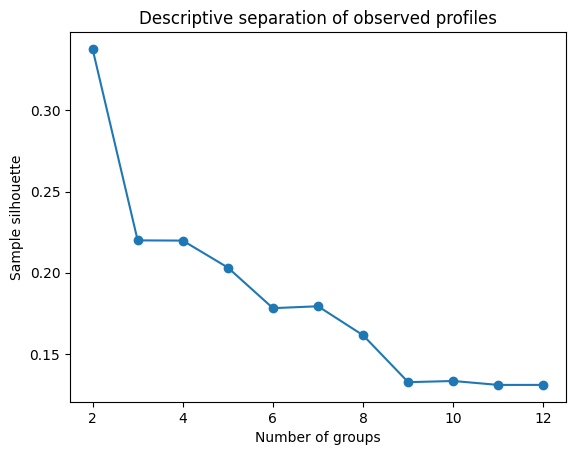

In [2]:
diagnostics = []
for count in range(2, 13):
    grouped = group_profiles(rec.X, rec.players, count)
    sizes = grouped.groupby('group').size()
    diagnostics.append({'groups': count, 'smallest_group': int(sizes.min()),
                        'largest_group': int(sizes.max()),
                        'silhouette_observed_sample': silhouette_score(rec.X, grouped.group, sample_size=600, random_state=42)})
diagnostics = pd.DataFrame(diagnostics)
display(diagnostics)
ax = diagnostics.plot(x='groups', y='silhouette_observed_sample', marker='o', legend=False)
ax.set(title='Descriptive separation of observed profiles', ylabel='Sample silhouette', xlabel='Number of groups')
plt.show()

## Interpreting a selected group

Inspect group sizes, positions and mean football measurements together. Standardized inputs give each measured feature influence, but correlated attacking features and missing measurements affect the geometry. Small groups can capture unusual statistical profiles or outliers rather than a useful recruitment category. Stable numbering does not make membership comparable across different markets. The six playing styles remain independent expert directions.

In [3]:
grouped = group_profiles(rec.X, rec.players, 6)
display(pd.crosstab(grouped.group, grouped.pos_main))
display(display_frame(grouped.groupby('group')[rec.artifacts.feature_cols].mean().round(2).reset_index()))
chosen_group = 1
display(display_frame(grouped[grouped.group.eq(chosen_group)][['player', 'team', 'league', 'pos_main', 'minutes']].head(20)))
np.testing.assert_array_equal(rec.artifacts.kmeans.cluster_centers_, centers_before)
assert sha256(model_path) == fingerprint_before
print('Saved trained clusters and model artifact unchanged.')

pos_main,DF,FW,MF
group,,,
1,454,2,113
2,202,16,79
3,95,11,180
4,10,145,112
5,12,84,77
6,1,188,29


,Grupo,Goles por 90 min,Asistencias por 90 min,Tiros por 90 min,Tiros a puerta por 90 min,Centros por 90 min,Intercepciones por 90 min,Entradas ganadas por 90 min,Faltas cometidas por 90 min,Faltas recibidas por 90 min
0,1,0.04,0.03,0.56,0.15,0.51,1.10,0.98,1.03,0.66
1,2,0.06,0.13,0.88,0.25,3.53,0.81,1.10,0.98,0.89
2,3,0.06,0.07,0.94,0.26,1.39,1.16,1.72,1.74,1.43
3,4,0.18,0.08,1.90,0.63,1.52,0.43,0.78,1.58,1.85
4,5,0.23,0.26,2.18,0.75,4.69,0.49,0.74,0.92,1.40
5,6,0.48,0.16,2.95,1.21,1.13,0.31,0.52,1.26,1.46


,Jugador,Equipo,Liga,Posición,Minutos
1,Kevin Kampl,RB Leipzig,Bundesliga,Centrocampista,1363.0
5,Manuel Gulde,Freiburg,Bundesliga,Defensa,2047.0
6,Anthony Jung,Werder Bremen,Bundesliga,Defensa,2579.0
14,Nico Elvedi,Gladbach,Bundesliga,Defensa,2482.0
18,Tim Drexler,Hoffenheim,Bundesliga,Defensa,573.0
19,Julian Chabot,Köln,Bundesliga,Defensa,2703.0
23,Willian Pacho,Eint Frankfurt,Bundesliga,Defensa,2970.0
31,Luca Kilian,Köln,Bundesliga,Defensa,635.0
32,Finn Ole Becker,Hoffenheim,Bundesliga,Centrocampista,606.0
35,Josip Stanišić,Leverkusen,Bundesliga,Defensa,1261.0


Saved trained clusters and model artifact unchanged.


## Limits and scouting use

Choose a grouping granularity to browse alternatives, inspect players in a selected group, and assess individuals against the scouting requirements. A high silhouette is not evidence of successful transfers or tactical suitability. The fixed 600-player sample supports reproducible descriptive diagnostics; conclusions about robustness should use the person-block analyses in notebook 11. No optimal group count is claimed here. Raw and processed datasets and the original experiment artifacts remain unchanged.